# COMP472 Project – Clustering (k-Means from scratch)

Clustering is **unsupervised**: k-Means groups the examples using the features only, **without looking at the labels**. Afterwards we compare the groups with the true labels to learn how the feature space is organised.

Questions from the project description that this notebook answers:

* Do sentiment examples naturally separate into Negative, Neutral and Positive groups?
* Do similar visual objects end up in the same clusters? Which classes are grouped together?
* How does the number of clusters change the results?
* How closely do the clusters match the true labels?

Plan

1. Load the data and preprocess it
2. k-Means written by us
3. How we measure cluster quality (purity, ARI, NMI)
4. Sentiment: 3 clusters, then other numbers of clusters
5. Image: 50 clusters, then other numbers of clusters
6. 2-D pictures with PCA

**Running time on a laptop:** about 5–10 minutes.

## 0. Imports

In [4]:
import os
import sys

# This notebook is in a sub-folder. Work from the project root: the folder
# that contains common.py, Project_info/, results/ and predictions/.
if not os.path.exists("common.py"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score   # metrics only

import common

os.makedirs("results/clustering", exist_ok=True)

## 1. Load and preprocess the data

Clustering does not train a classifier, so we do not need a validation split: we cluster **all 20,000 image** and **all 12,000 sentiment** training examples. The labels are used only at the end, to evaluate the clusters.

Same preprocessing as for k-NN, because k-Means is also based on distances:

* sentiment → `standardize` (BERT features have very different scales)
* image → `sqrt` (square root, then every row has length 1)

In [5]:
X_image_raw, y_image, _, _ = common.load_task("image")
X_sent_raw, y_sent, _, _ = common.load_task("sentiment")

def preprocess(X, mode):
    stats = common.fit_preprocessing(X, mode)
    return common.apply_preprocessing(X, mode, stats)

X_sent = preprocess(X_sent_raw, "standardize")
X_image = preprocess(X_image_raw, "sqrt")
print("sentiment:", X_sent.shape, "| image:", X_image.shape)

sentiment: (12000, 768) | image: (20000, 500)


## 2. k-Means

1. **Start:** choose k first cluster centres (see below).
2. **Assign:** put every example in the cluster of its closest centre (Euclidean distance).
3. **Update:** move every centre to the mean of the examples in its cluster.
4. Repeat 2–3 until the centres stop moving (or `max_iter` is reached).

If a cluster ends up empty, its centre is moved to a random example.

**Choosing the first centres** – two options:

* `"random"`: k random examples. Simple, but two first centres can land in the same group, and k-Means then gets stuck in a poor solution.
* `"k-means++"`: the first centre is a random example; every next centre is picked at random **with probability proportional to its squared distance to the nearest centre already chosen**. Far-away examples are more likely to be picked, so the first centres are spread over the data. This usually gives better clusters.

k-Means only finds a *local* best solution that depends on the start, so we run it `n_init` times with different seeds and keep the run with the smallest **inertia** (sum of squared distances from each example to its centre; smaller = tighter clusters).

Squared distances use $\lVert x-c\rVert^2 = \lVert x\rVert^2 - 2\,x\cdot c + \lVert c\rVert^2$, so the main work is one matrix product.

In [6]:
def squared_distances(X, centers):
    return (X ** 2).sum(axis=1)[:, None] - 2 * X @ centers.T + (centers ** 2).sum(axis=1)[None, :]


def kmeans_plus_plus_start(X, k, rng):
    centers = [X[rng.integers(len(X))]]                        # first centre: random example
    closest = ((X - centers[0]) ** 2).sum(axis=1)              # squared distance to the nearest centre so far
    for _ in range(1, k):
        probabilities = closest / closest.sum()                # far examples are more likely
        new_center = X[rng.choice(len(X), p=probabilities)]
        centers.append(new_center)
        closest = np.minimum(closest, ((X - new_center) ** 2).sum(axis=1))
    return np.array(centers)


def kmeans_once(X, k, seed, max_iter=100, init="k-means++"):
    rng = np.random.default_rng(seed)
    if init == "random":                                              # 1. start
        centers = X[rng.choice(len(X), size=k, replace=False)].copy()
    else:
        centers = kmeans_plus_plus_start(X, k, rng)

    for iteration in range(1, max_iter + 1):
        labels = squared_distances(X, centers).argmin(axis=1)         # 2. assign

        new_centers = np.zeros_like(centers)                          # 3. update
        for c in range(k):
            members = X[labels == c]
            if len(members) > 0:
                new_centers[c] = members.mean(axis=0)
            else:
                new_centers[c] = X[rng.integers(len(X))]              # empty cluster

        moved = np.abs(new_centers - centers).max()
        centers = new_centers
        if moved < 1e-6:                                              # 4. centres stopped moving
            break

    D = squared_distances(X, centers)
    labels = D.argmin(axis=1)
    inertia = D[np.arange(len(X)), labels].sum()
    return labels, centers, inertia, iteration


def kmeans(X, k, n_init=3, max_iter=100, init="k-means++"):
    best = None
    for seed in range(n_init):
        labels, centers, inertia, iterations = kmeans_once(X, k, seed, max_iter, init)
        if best is None or inertia < best[2]:
            best = (labels, centers, inertia, iterations)
    return best

## 3. Measuring how well clusters match the labels

* **Contingency table:** row = cluster, column = true class, cell = how many examples of that class are in that cluster.
* **Purity:** give every cluster the label of its most common class, then count how many examples are correct. 1.0 = every cluster contains a single class. Warning: purity tends to go up when k goes up (with one cluster per example it would be 1.0), so it is only fair to compare purity for the same k.
* **ARI** (Adjusted Rand Index): 1.0 = perfect match, about 0 = no better than random clusters. It is adjusted for chance, so it can be compared across different k.
* **NMI** (Normalised Mutual Information): 0 = the clusters tell us nothing about the labels, 1 = perfect.

The project allows metrics from libraries, so ARI and NMI come from `sklearn.metrics`; purity and the contingency table we compute ourselves.

In [7]:
def contingency_table(cluster_labels, true_labels, k, n_classes):
    table = np.zeros((k, n_classes), dtype=int)
    for c, t in zip(cluster_labels, true_labels):
        table[c][t] += 1
    return table


def purity(table):
    return table.max(axis=1).sum() / table.sum()     # biggest class in each cluster


def evaluate(cluster_labels, true_labels, k, n_classes):
    table = contingency_table(cluster_labels, true_labels, k, n_classes)
    return {
        "purity": round(purity(table), 4),
        "ARI": round(adjusted_rand_score(true_labels, cluster_labels), 4),
        "NMI": round(normalized_mutual_info_score(true_labels, cluster_labels), 4),
    }, table


all_results = []

def run(task, X, y, k, note="", init="k-means++"):
    n_classes = common.N_CLASSES[task]
    start = time.time()
    labels, centers, inertia, iterations = kmeans(X, k, init=init)
    scores, table = evaluate(labels, y, k, n_classes)
    row = {"task": task, "k": k, "note": note, "inertia": round(float(inertia), 1),
           "iterations": iterations, **scores, "seconds": round(time.time() - start, 1)}
    all_results.append(row)
    print(f"{task:<9} k={k:<4} {note:<12} purity {scores['purity']:.3f}   ARI {scores['ARI']:.3f}"
          f"   NMI {scores['NMI']:.3f}   inertia {inertia:.0f}   ({row['seconds']}s)")
    return labels, table

## 4. Sentiment

### 4.1 Three clusters – do they match Negative / Neutral / Positive?

If the BERT features naturally separated the three sentiments, each cluster would be mostly one sentiment (purity close to 1, ARI close to 1).

sentiment k=3                 purity 0.423   ARI 0.020   NMI 0.019   inertia 8674730   (4.9s)


,Negative,Neutral,Positive,size
cluster 0,2270,1612,1488,5370
cluster 1,389,760,465,1614
cluster 2,1341,1628,2047,5016


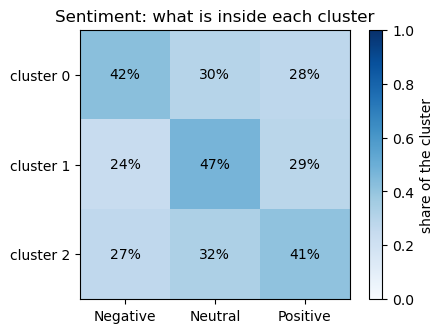

In [8]:
sent_clusters, table = run("sentiment", X_sent, y_sent, 3)

table_df = pd.DataFrame(table, columns=common.SENTIMENT_NAMES,
                        index=[f"cluster {c}" for c in range(3)])
table_df["size"] = table_df.sum(axis=1)
display(table_df)

# Share of each sentiment inside every cluster
shares = table / table.sum(axis=1, keepdims=True)
plt.figure(figsize=(5, 3.5))
plt.imshow(shares, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="share of the cluster")
plt.xticks(range(3), common.SENTIMENT_NAMES)
plt.yticks(range(3), [f"cluster {c}" for c in range(3)])
for i in range(3):
    for j in range(3):
        plt.text(j, i, f"{shares[i, j]:.0%}", ha="center", va="center")
plt.title("Sentiment: what is inside each cluster")
plt.show()

*For the report: if every cluster contains roughly 1/3 of each sentiment, the main structure of the BERT features is **not** sentiment (it could be topic, length, style…). This also explains why the classifiers find sentiment hard, especially Neutral.*

### 4.2 Changing the number of clusters

In [9]:
for k in [2, 3, 4, 5, 6, 8, 10]:
    _ = run("sentiment", X_sent, y_sent, k)

sentiment k=2                 purity 0.391   ARI 0.014   NMI 0.012   inertia 8880832   (4.3s)
sentiment k=3                 purity 0.423   ARI 0.020   NMI 0.019   inertia 8674730   (4.8s)
sentiment k=4                 purity 0.435   ARI 0.026   NMI 0.025   inertia 8522742   (4.9s)
sentiment k=5                 purity 0.420   ARI 0.022   NMI 0.028   inertia 8386106   (7.4s)
sentiment k=6                 purity 0.420   ARI 0.022   NMI 0.026   inertia 8290176   (12.4s)
sentiment k=8                 purity 0.444   ARI 0.024   NMI 0.031   inertia 8120141   (17.3s)
sentiment k=10                purity 0.444   ARI 0.025   NMI 0.034   inertia 7991219   (24.1s)


## 5. Image

### 5.1 Fifty clusters (one per class, if the classes were perfectly separated)

Two quick checks first: raw features vs `sqrt` features, and random start vs k-means++ start.

In [10]:
_ = run("image", preprocess(X_image_raw, "none"), y_image, 50, note="raw")
_ = run("image", X_image, y_image, 50, note="random start", init="random")
image_clusters, image_table = run("image", X_image, y_image, 50, note="sqrt")

image     k=50   raw          purity 0.104   ARI 0.023   NMI 0.113   inertia 14588   (25.9s)
image     k=50   random start purity 0.105   ARI 0.026   NMI 0.123   inertia 14864   (17.4s)
image     k=50   sqrt         purity 0.107   ARI 0.024   NMI 0.121   inertia 14871   (27.4s)


### 5.2 Which classes are grouped together?

For every class we find the cluster that holds most of its images (its *main cluster*). Classes that share the same main cluster look alike to k-Means. Compare these groups with the most confused pairs of the classifiers (k-NN / NN confusion matrices).

Clusters that are the main cluster of SEVERAL classes:
  cluster 13: classes [0, 6, 7, 14, 27, 29]
  cluster 16: classes [1, 9, 22, 47]
  cluster 38: classes [10, 38, 42, 44]
  cluster  2: classes [2, 3, 4]
  cluster  5: classes [15, 17, 41]
  cluster 36: classes [18, 24, 43]
  cluster 37: classes [5, 20]
  cluster 28: classes [11, 33]
  cluster 22: classes [12, 25]
  cluster 18: classes [16, 35]
  cluster 31: classes [21, 23]
  cluster 11: classes [36, 49]

Classes most spread over many clusters: [(43, '6%'), (47, '6%'), (41, '6%'), (40, '6%'), (29, '6%')]
Classes most concentrated in one cluster: [(2, '29%'), (45, '30%'), (13, '35%'), (48, '35%'), (46, '36%')]


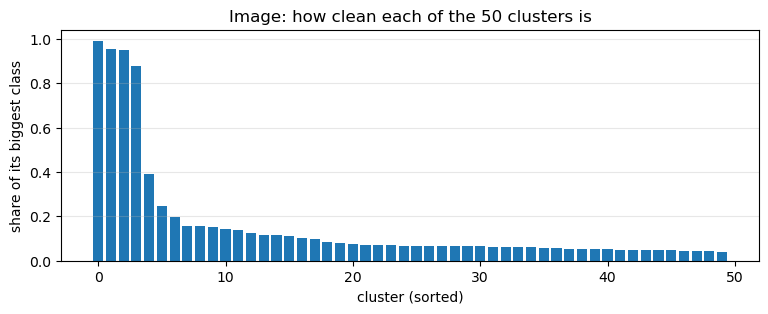

In [11]:
main_cluster = image_table.argmax(axis=0)          # for every class: the cluster with most of its images
share_in_main = image_table.max(axis=0) / image_table.sum(axis=0)

groups = {}
for cls in range(50):
    groups.setdefault(int(main_cluster[cls]), []).append(cls)

print("Clusters that are the main cluster of SEVERAL classes:")
for cluster, classes in sorted(groups.items(), key=lambda g: -len(g[1])):
    if len(classes) > 1:
        print(f"  cluster {cluster:2d}: classes {classes}")

order = np.argsort(share_in_main)
print("\nClasses most spread over many clusters:", [(int(c), f"{share_in_main[c]:.0%}") for c in order[:5]])
print("Classes most concentrated in one cluster:", [(int(c), f"{share_in_main[c]:.0%}") for c in order[-5:]])

# Purity of every cluster (how 'clean' it is)
cluster_purity = image_table.max(axis=1) / np.maximum(image_table.sum(axis=1), 1)
plt.figure(figsize=(9, 3))
plt.bar(range(50), np.sort(cluster_purity)[::-1])
plt.xlabel("cluster (sorted)")
plt.ylabel("share of its biggest class")
plt.title("Image: how clean each of the 50 clusters is")
plt.grid(axis="y", alpha=0.3)
plt.show()

### 5.3 Changing the number of clusters

In [12]:
for k in [10, 25, 50, 75, 100]:
    _ = run("image", X_image, y_image, k)

image     k=10                purity 0.049   ARI 0.009   NMI 0.041   inertia 15590   (30.0s)
image     k=25                purity 0.079   ARI 0.018   NMI 0.092   inertia 15171   (24.3s)
image     k=50                purity 0.107   ARI 0.024   NMI 0.121   inertia 14871   (27.7s)
image     k=75                purity 0.127   ARI 0.028   NMI 0.145   inertia 14727   (31.7s)
image     k=100               purity 0.138   ARI 0.030   NMI 0.161   inertia 14604   (23.3s)


### Summary table and elbow plots

**Elbow method:** inertia always goes down when k goes up. Where the curve bends (the "elbow"), adding clusters stops helping much; that k is a reasonable number of natural groups.

,task,k,note,inertia,iterations,purity,ARI,NMI,seconds
0,sentiment,3,,8674730.0,18,0.4231,0.0203,0.0190,4.9
1,sentiment,2,,8880832.0,26,0.3913,0.0137,0.0117,4.3
2,sentiment,3,,8674730.0,18,0.4231,0.0203,0.0190,4.8
3,sentiment,4,,8522742.0,22,0.4351,0.0258,0.0247,4.9
4,sentiment,5,,8386105.5,43,0.4204,0.0219,0.0277,7.4
5,sentiment,6,,8290176.5,32,0.4205,0.0217,0.0265,12.4
6,sentiment,8,,8120141.0,56,0.4438,0.0237,0.0307,17.3
7,sentiment,10,,7991219.0,79,0.4443,0.0248,0.0339,24.1
8,image,50,raw,14588.4,55,0.1042,0.0231,0.1126,25.9
9,image,50,random start,14864.5,44,0.1052,0.0261,0.1232,17.4


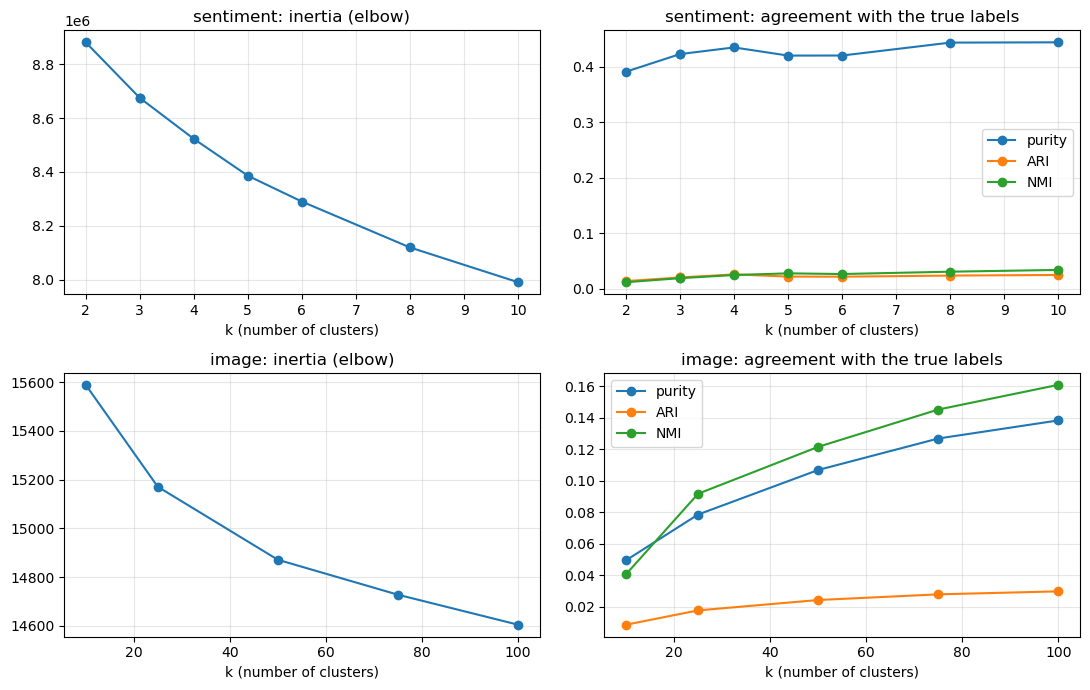

In [13]:
results = pd.DataFrame(all_results)
results.to_csv("results/clustering/clustering_results.csv", index=False)
display(results)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, task in enumerate(["sentiment", "image"]):
    r = results[(results["task"] == task) & (results["note"] == "")].sort_values("k")   # rows of 4.2 and 5.3
    axes[row, 0].plot(r["k"], r["inertia"], marker="o")
    axes[row, 0].set_title(f"{task}: inertia (elbow)")
    axes[row, 1].plot(r["k"], r["purity"], marker="o", label="purity")
    axes[row, 1].plot(r["k"], r["ARI"], marker="o", label="ARI")
    axes[row, 1].plot(r["k"], r["NMI"], marker="o", label="NMI")
    axes[row, 1].set_title(f"{task}: agreement with the true labels")
    axes[row, 1].legend()
    for ax in axes[row]:
        ax.set_xlabel("k (number of clusters)")
        ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Pictures in 2-D with PCA

The features have 500 or 768 dimensions, so we cannot plot them directly. **PCA** finds the 2 directions in which the data varies the most; we project every example onto them. (Written with NumPy: centre the data, then take the first 2 right singular vectors of the SVD.)

Points that overlap in 2-D may still be separated in the full space, so these pictures are only a rough view.

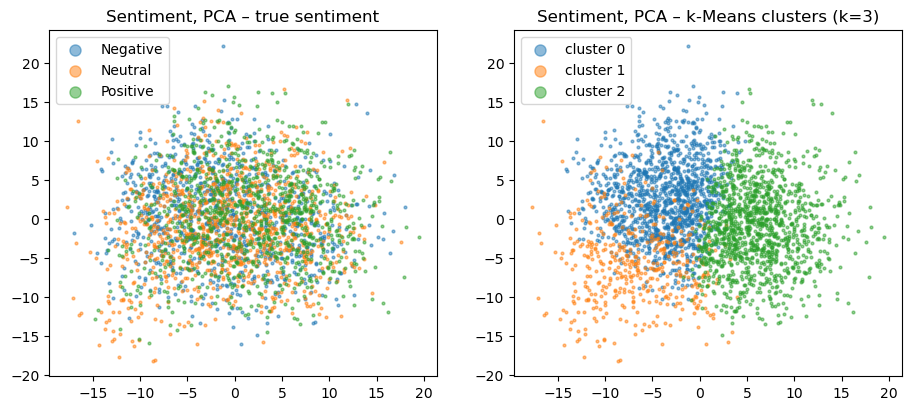

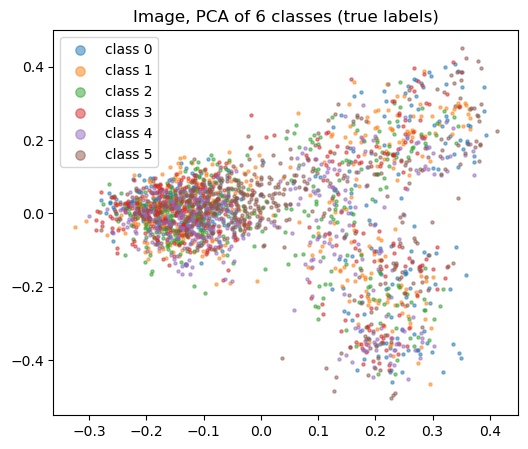

In [14]:
def pca_2d(X):
    centered = X - X.mean(axis=0)
    _, _, Vt = np.linalg.svd(centered, full_matrices=False)
    return centered @ Vt[:2].T


rng = np.random.default_rng(42)

# Sentiment: true labels vs 3 clusters
sample = rng.choice(len(X_sent), min(3000, len(X_sent)), replace=False)   # 3000 points are enough to see
P = pca_2d(X_sent)[sample]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, colors, title in [(axes[0], y_sent[sample], "true sentiment"),
                          (axes[1], sent_clusters[sample], "k-Means clusters (k=3)")]:
    for c in range(3):
        name = common.SENTIMENT_NAMES[c] if title == "true sentiment" else f"cluster {c}"
        ax.scatter(P[colors == c, 0], P[colors == c, 1], s=4, alpha=0.5, label=name)
    ax.set_title(f"Sentiment, PCA – {title}")
    ax.legend(markerscale=4)
plt.show()

# Image: 6 classes only, otherwise the plot is unreadable
classes_to_show = [0, 1, 2, 3, 4, 5]
mask = np.isin(y_image, classes_to_show)
P = pca_2d(X_image[mask])
plt.figure(figsize=(6, 5))
for c in classes_to_show:
    plt.scatter(P[y_image[mask] == c, 0], P[y_image[mask] == c, 1], s=5, alpha=0.5, label=f"class {c}")
plt.title("Image, PCA of 6 classes (true labels)")
plt.legend(markerscale=3)
plt.show()

## Notes for the presentation

* k-Means does not use the labels, so agreement with them shows how much the **features themselves** separate the classes.
* Compare the image class groups found in 5.2 with the most confused pairs of k-NN: classes that share clusters are usually also the ones the classifiers mix up.
* Low agreement for sentiment means the classes are not separate "blobs" in the BERT space, which is why a supervised model (k-NN with many neighbours, or the neural network) is needed.